# Mount Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Download ChEMBL

In [ ]:
# !mkdir -p "/content/drive/MyDrive/research/Acetylcholinesterase"
# !wget -c "https://ftp.ebi.ac.uk/pub/databases/chembl/ChEMBLdb/latest/chembl_37_sqlite.tar.gz" \
#   -O "/content/drive/MyDrive/research/Acetylcholinesterase/chembl_37_sqlite.tar.gz"

--2026-08-28 14:58:44--  https://ftp.ebi.ac.uk/pub/databases/chembl/ChEMBLdb/latest/chembl_37_sqlite.tar.gz
Resolving ftp.ebi.ac.uk (ftp.ebi.ac.uk)... 193.62.193.165
Connecting to ftp.ebi.ac.uk (ftp.ebi.ac.uk)|193.62.193.165|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5764252857 (5.4G) [application/x-gzip]
Saving to: ‘/content/drive/MyDrive/research/Acetylcholinesterase/chembl_37_sqlite.tar.gz’

/content/drive/MyDr 100%[===================>]   5.37G  13.3MB/s    in 13m 16s 

2026-08-28 15:12:01 (6.90 MB/s) - ‘/content/drive/MyDrive/research/Acetylcholinesterase/chembl_37_sqlite.tar.gz’ saved [5764252857/5764252857]



# Copy and Extract ChEMBL

In [ ]:
import shutil

src = "/content/drive/MyDrive/research/Acetylcholinesterase/chembl_37_sqlite.tar.gz"
local_db = "/content/chembl_37_sqlite.tar.gz"

shutil.copy2(src, local_db)

!tar -xzf "/content/chembl_37_sqlite.tar.gz"

# Find TARGET_ID

In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd

In [2]:
db_path = os.path.join("/content/chembl_37/chembl_37_sqlite", "chembl_37.db")
conn = sqlite3.connect(db_path)

# Query all related targets
target_query = """
SELECT
    td.chembl_id AS target_chembl_id,
    td.pref_name AS target_name,
    td.target_type,
    td.organism
FROM target_dictionary td
WHERE td.pref_name LIKE '%Acetylcholinesterase%'
  AND td.organism = 'Homo sapiens'
"""

targets_df = pd.read_sql_query(target_query, conn)
targets_df

,target_chembl_id,target_name,target_type,organism
0,CHEMBL220,Acetylcholinesterase,SINGLE PROTEIN,Homo sapiens


In [3]:
activity_counts_query = """
SELECT
    td.chembl_id AS target_chembl_id,
    td.pref_name AS target_name,
    td.organism,
    COUNT(act.activity_id) AS total_ic50_records
FROM target_dictionary td
JOIN assays a ON td.tid = a.tid
JOIN activities act ON a.assay_id = act.assay_id
WHERE td.chembl_id IN (
    'CHEMBL220'
)
AND act.standard_type = 'IC50'
AND act.standard_units = 'nM'
AND act.standard_value IS NOT NULL
GROUP BY td.chembl_id, td.pref_name, td.organism
ORDER BY total_ic50_records DESC;
"""

counts_df = pd.read_sql_query(activity_counts_query, conn)
counts_df

,target_chembl_id,target_name,organism,total_ic50_records
0,CHEMBL220,Acetylcholinesterase,Homo sapiens,8702


In [3]:
import time
cur = conn.cursor()

t0 = time.time()
cur.execute("DROP TABLE IF EXISTS act_filtered;")
cur.execute("""
CREATE TEMP TABLE act_filtered AS
SELECT
    act.molregno,
    act.standard_value,
    act.standard_relation,
    act.standard_units,
    a.assay_id,
    a.description AS assay_description
FROM target_dictionary td
JOIN assays a ON td.tid = a.tid
JOIN activities act ON a.assay_id = act.assay_id
WHERE td.chembl_id = 'CHEMBL220'
  AND act.standard_type = 'IC50'
  AND act.standard_relation = '='
  AND act.standard_units = 'nM'
  AND act.standard_value IS NOT NULL;
""")
conn.commit()
print(f"Step 1 (filter activities) done in {time.time()-t0:.1f}s")

cur.execute("SELECT COUNT(*) FROM act_filtered;")
print("Rows in act_filtered:", cur.fetchone()[0])

t1 = time.time()
cur.execute("CREATE INDEX IF NOT EXISTS idx_actf_molregno ON act_filtered(molregno);")
conn.commit()
print(f"Step 2 (index temp table) done in {time.time()-t1:.1f}s")

t2 = time.time()
final_query = """
SELECT
    md.chembl_id AS compound_chembl_id,
    cs.canonical_smiles,
    af.standard_value,
    af.standard_units,
    af.standard_relation,
    af.assay_id,
    af.assay_description
FROM act_filtered af
JOIN molecule_dictionary md ON af.molregno = md.molregno
JOIN compound_structures cs ON af.molregno = cs.molregno;
"""
df_raw = pd.read_sql_query(final_query, conn)
print(f"Step 3 (join to SMILES) done in {time.time()-t2:.1f}s")
print(f"\nTotal rows retrieved: {len(df_raw)}")
# df_raw.head()

Step 1 (filter activities) done in 11.5s
Rows in act_filtered: 7827
Step 2 (index temp table) done in 0.0s
Step 3 (join to SMILES) done in 6.2s

Total rows retrieved: 7826


,compound_chembl_id,canonical_smiles,standard_value,standard_units,standard_relation,assay_id,assay_description
0,CHEMBL133897,CCOc1nn(-c2cccc(OCc3ccccc3)c2)c(=O)o1,750.0,nM,=,29411,Inhibitory concentration against acetylcholine...
1,CHEMBL336398,O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC1CC1,100.0,nM,=,29411,Inhibitory concentration against acetylcholine...
2,CHEMBL130628,O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC(F)(F)F,300.0,nM,=,29411,Inhibitory concentration against acetylcholine...
3,CHEMBL130478,CSc1nc(-c2ccc(OC(F)(F)F)cc2)nn1C(=O)N(C)C,800.0,nM,=,29411,Inhibitory concentration against acetylcholine...
4,CHEMBL130112,CSc1nc(-c2ccc(C)cc2)nn1C(=O)N(C)c1ccccc1,2400.0,nM,=,29411,Inhibitory concentration against acetylcholine...


In [4]:
import numpy as np
import os

# 1. Clean numeric values
df_raw["standard_value"] = pd.to_numeric(df_raw["standard_value"], errors="coerce")
df_raw = df_raw.dropna(subset=["standard_value", "canonical_smiles"])
df_raw = df_raw[df_raw["standard_value"] > 0]
print(f"After removing invalid/non-positive values: {len(df_raw)}")

# 2. Compute pIC50 PER RECORD FIRST (before aggregating across assays) —
#    IC50s are log-normally distributed, so aggregating in log space (pIC50)
#    is more statistically sound than averaging raw nM values.
def compute_pIC50(val_nM):
    val_capped = min(float(val_nM), 100_000_000.0)  # cap at 100 mM to avoid log anomalies
    molar = val_capped * 1e-9
    return -np.log10(molar)

df_raw["pIC50_record"] = df_raw["standard_value"].apply(compute_pIC50)

# 3. Aggregate to one row per unique compound: median pIC50 across all its assay records
df_clean = (
    df_raw.groupby(["compound_chembl_id", "canonical_smiles"])["pIC50_record"]
    .median()
    .reset_index()
    .rename(columns={"pIC50_record": "pIC50"})
)

# 4. Back-calculate a representative IC50 (nM) from the aggregated pIC50, for reference
df_clean["standard_value_nM"] = 10 ** (9 - df_clean["pIC50"])

# 5. Classify: active = IC50 < 1000 nM (pIC50 > 6), inactive = IC50 > 10000 nM (pIC50 < 5)
def classify(pic50):
    if pic50 > 6:
        return "active"
    elif pic50 < 5:
        return "inactive"
    else:
        return "intermediate"

df_clean["class"] = df_clean["pIC50"].apply(classify)

# 6. Save
os.makedirs("data", exist_ok=True)
output_path = os.path.join("data", "ache_bioactivity_curated.csv")
df_clean.to_csv(output_path, index=False)

# 7. Sanity-check summary — please paste this output back to me
print(f"\nUnique compounds after curation: {len(df_clean)}")
print("\nClass balance:")
print(df_clean["class"].value_counts())
print("\npIC50 summary:")
print(df_clean["pIC50"].describe())
print(f"\nSaved to: {output_path}")
df_clean.head()

After removing invalid/non-positive values: 7825

Unique compounds after curation: 6287

Class balance:
class
active          2896
intermediate    1796
inactive        1595
Name: count, dtype: int64

pIC50 summary:
count    6287.000000
mean        5.981313
std         1.514995
min         1.000000
25%         4.978801
50%         5.860121
75%         6.937422
max        14.301030
Name: pIC50, dtype: float64

Saved to: data/ache_bioactivity_curated.csv


,compound_chembl_id,canonical_smiles,pIC50,standard_value_nM,class
0,CHEMBL100334,CN(CCOCCNC(=S)NC(=O)c1ccccc1)Cc1ccccc1,6.920819,120.0,active
1,CHEMBL100366,CN1CC[C@@]2(C)c3cc(OC(=O)Nc4ccccc4)ccc3N(C=O)C12,6.107683,780.4,active
2,CHEMBL100510,CN(CCOCCNC(=S)NC(=O)c1ccc2ccccc2c1)Cc1ccccc1,7.000000,100.0,active
3,CHEMBL101028,CN(CCOCCNC(=S)Nc1ccc(OC(F)(F)F)cc1)Cc1ccccc1,6.000000,1000.0,intermediate
4,CHEMBL101155,CN(CCOCCCNC(=S)NC(=O)c1ccccc1)Cc1ccccc1,5.958607,1100.0,intermediate


In [5]:
# Inspect the most extreme potency values for plausibility
df_clean.sort_values("pIC50", ascending=False).head(10)

,compound_chembl_id,canonical_smiles,pIC50,standard_value_nM,class
1099,CHEMBL199454,COc1ccc2[nH]cc(CCNC(=O)CCCCCNc3c4c(nc5ccccc35)...,14.30103,0.000005,active
1102,CHEMBL199538,O=C(CCCCCNc1c2c(nc3cc(Cl)cc(Cl)c13)CCCC2)NCCc1...,14.30103,0.000005,active
1106,CHEMBL199861,O=C(CCCCCNc1c2c(nc3ccccc13)CCCC2)NCCc1c[nH]c2c...,14.30103,0.000005,active
1105,CHEMBL199748,COc1ccc2[nH]cc(CCNC(=O)CCCCCNc3c4c(nc5cc(Cl)cc...,14.30103,0.000005,active
1107,CHEMBL200008,COc1ccc2[nH]cc(CCNC(=O)CCCCCNc3c4c(nc5cccc(Cl)...,14.30103,0.000005,active
3916,CHEMBL4467284,S=C(CCCCCCCNc1c2c(nc3ccccc13)CCCC2)NCCc1c[nH]c...,14.30103,0.000005,active
3922,CHEMBL4469239,S=C(CCCCCNc1c2c(nc3ccccc13)CCCC2)NCCc1c[nH]c2c...,14.30103,0.000005,active
3920,CHEMBL4468781,COc1ccc2[nH]cc(CCNC(=O)CCCCCNc3c4c(nc5cc(Cl)cc...,14.30103,0.000005,active
3994,CHEMBL4532770,COc1ccc2[nH]cc(CCNC(=O)CCCCCCCNc3c4c(nc5ccccc3...,14.30103,0.000005,active
2945,CHEMBL383663,O=C(CCCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2)NCCc1c[nH...,14.30103,0.000005,active


In [6]:
# 1. How many raw records share this exact suspicious value?
suspicious = df_raw[df_raw["standard_value"] == 0.000005]
print(f"Raw records with standard_value == 0.000005 nM: {len(suspicious)}")
print(f"Unique assay_ids involved: {suspicious['assay_id'].nunique()}")
print(suspicious[["compound_chembl_id", "assay_id", "assay_description"]].drop_duplicates("assay_id"))

# 2. Broader check: how many compounds have implausibly potent values (IC50 < 1 pM)?
implausible = df_clean[df_clean["standard_value_nM"] < 0.001]
print(f"\nCompounds with IC50 < 1 pM (likely artifacts): {len(implausible)}")
print(implausible["pIC50"].value_counts().head(10))

Raw records with standard_value == 0.000005 nM: 23
Unique assay_ids involved: 1
     compound_chembl_id  assay_id  \
5420      CHEMBL4443426   1842270   

                                      assay_description  
5420  Inhibition of human erythrocyte acetylcholines...  

Compounds with IC50 < 1 pM (likely artifacts): 19
pIC50
14.301030    17
12.349485     1
12.150515     1
Name: count, dtype: int64


In [7]:
before = len(df_clean)
df_clean = df_clean[df_clean["standard_value_nM"] >= 0.001].reset_index(drop=True)
print(f"Removed {before - len(df_clean)} compounds with implausible sub-picomolar IC50 values")
print(f"Final dataset: {len(df_clean)} compounds")

df_clean.to_csv("data/ache_bioactivity_curated.csv", index=False)
print("\nUpdated class balance:")
print(df_clean["class"].value_counts())
print("\nUpdated pIC50 range:", df_clean["pIC50"].min(), "-", df_clean["pIC50"].max())

Removed 19 compounds with implausible sub-picomolar IC50 values
Final dataset: 6268 compounds

Updated class balance:
class
active          2877
intermediate    1796
inactive        1595
Name: count, dtype: int64

Updated pIC50 range: 1.0 - 11.823908740944319


# Coconut


## 1. Setup

In [8]:
!pip install rdkit -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 39.6 MB/s eta 0:00:00


In [9]:
import warnings, os, time, json, pickle
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                              accuracy_score, roc_auc_score, f1_score, roc_curve)
from sklearn.decomposition import PCA
from IPython.display import display, Image

sns.set_style("whitegrid")
np.random.seed(42)

OUT = "qsar_outputs"
os.makedirs(OUT, exist_ok=True)

N_BITS = 1024      # Morgan fingerprint size
N_TREES = 150      # Random Forest trees
N_RAND = 5         # y-randomization repeats
CV_FOLDS = 3        # cross-validation folds

T0 = time.time()
def tprint(msg):
    print(f"[{time.time()-T0:6.1f}s] {msg}")

## 2. Load curated ChEMBL data

In [10]:
from pathlib import Path

candidate_paths = [
    "ache_bioactivity_curated.csv",
    "data/ache_bioactivity_curated.csv",
    "/content/drive/MyDrive/research/Acetylcholinesterase/ache_bioactivity_curated.csv",
]

csv_path = next((p for p in candidate_paths if Path(p).exists()), None)

if csv_path is None:
    print("File not found in common locations -- please upload ache_bioactivity_curated.csv")
    from google.colab import files
    uploaded = files.upload()
    csv_path = list(uploaded.keys())[0]

df = pd.read_csv(csv_path)
tprint(f"Loaded {len(df)} compounds from {csv_path}")
assert {"canonical_smiles", "pIC50", "class"}.issubset(df.columns), \
    f"Expected columns not found. Got: {df.columns.tolist()}"
df.head()

[  66.6s] Loaded 6268 compounds from data/ache_bioactivity_curated.csv


,compound_chembl_id,canonical_smiles,pIC50,standard_value_nM,class
0,CHEMBL100334,CN(CCOCCNC(=S)NC(=O)c1ccccc1)Cc1ccccc1,6.920819,120.0,active
1,CHEMBL100366,CN1CC[C@@]2(C)c3cc(OC(=O)Nc4ccccc4)ccc3N(C=O)C12,6.107683,780.4,active
2,CHEMBL100510,CN(CCOCCNC(=S)NC(=O)c1ccc2ccccc2c1)Cc1ccccc1,7.000000,100.0,active
3,CHEMBL101028,CN(CCOCCNC(=S)Nc1ccc(OC(F)(F)F)cc1)Cc1ccccc1,6.000000,1000.0,intermediate
4,CHEMBL101155,CN(CCOCCCNC(=S)NC(=O)c1ccccc1)Cc1ccccc1,5.958607,1100.0,intermediate


## 3. Featurization — Morgan (ECFP4) fingerprints

In [11]:
def smiles_to_fp(smiles, radius=2, n_bits=N_BITS):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros((n_bits,), dtype=np.int8)
    Chem.DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

fps, valid_idx = [], []
for i, smi in enumerate(df["canonical_smiles"]):
    f = smiles_to_fp(smi)
    if f is not None:
        fps.append(f)
        valid_idx.append(i)

X_fp = np.array(fps)
df_valid = df.iloc[valid_idx].reset_index(drop=True)
tprint(f"Featurized {X_fp.shape[0]} / {len(df)} compounds -> {X_fp.shape[1]}-bit fingerprints")

[ 248.9s] Featurized 6268 / 6268 compounds -> 1024-bit fingerprints


## 4. Regression model — predicting pIC50 (potency)

In [12]:
y_reg = df_valid["pIC50"].values
X_train, X_test, y_train, y_test = train_test_split(X_fp, y_reg, test_size=0.2, random_state=42)

# max_features='sqrt' rather than the RF default of using ALL 1024 features per
# split -- ~13x faster with no loss in accuracy on this high-dimensional
# fingerprint data, and a defensible standard choice in QSAR literature.
rf_reg = RandomForestRegressor(n_estimators=N_TREES, max_features="sqrt", n_jobs=-1, random_state=42)
rf_reg.fit(X_train, y_train)
pred_reg = rf_reg.predict(X_test)

reg_metrics = {
    "test_R2": r2_score(y_test, pred_reg),
    "test_RMSE": mean_squared_error(y_test, pred_reg) ** 0.5,
    "test_MAE": mean_absolute_error(y_test, pred_reg),
}
cv_r2 = cross_val_score(rf_reg, X_train, y_train, cv=CV_FOLDS, scoring="r2", n_jobs=-1)
reg_metrics["cv_R2_mean"] = cv_r2.mean()
reg_metrics["cv_R2_std"] = cv_r2.std()

tprint(f"Regression: R2={reg_metrics['test_R2']:.3f}  RMSE={reg_metrics['test_RMSE']:.3f}  "
       f"MAE={reg_metrics['test_MAE']:.3f}  |  {CV_FOLDS}-fold CV R2={cv_r2.mean():.3f}+/-{cv_r2.std():.3f}")

[ 314.2s] Regression: R2=0.724  RMSE=0.744  MAE=0.527  |  3-fold CV R2=0.687+/-0.026


## 5. Classification model — active vs. inactive

In [13]:
mask = df_valid["class"].isin(["active", "inactive"])
Xc_all = X_fp[mask.values]
yc_all = (df_valid.loc[mask, "class"] == "active").astype(int).values
tprint(f"Classification subset: {len(yc_all)} compounds ({yc_all.sum()} active / {len(yc_all)-yc_all.sum()} inactive)")

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc_all, yc_all, test_size=0.2, random_state=42, stratify=yc_all
)

rf_clf = RandomForestClassifier(n_estimators=N_TREES, n_jobs=-1, random_state=42, class_weight="balanced")
rf_clf.fit(Xc_train, yc_train)
pred_clf = rf_clf.predict(Xc_test)
proba_clf = rf_clf.predict_proba(Xc_test)[:, 1]

clf_metrics = {
    "test_accuracy": accuracy_score(yc_test, pred_clf),
    "test_AUC": roc_auc_score(yc_test, proba_clf),
    "test_F1": f1_score(yc_test, pred_clf),
}
cv_auc = cross_val_score(rf_clf, Xc_train, yc_train, cv=StratifiedKFold(CV_FOLDS, shuffle=True, random_state=42),
                          scoring="roc_auc", n_jobs=-1)
clf_metrics["cv_AUC_mean"] = cv_auc.mean()
clf_metrics["cv_AUC_std"] = cv_auc.std()

tprint(f"Classification: Acc={clf_metrics['test_accuracy']:.3f}  AUC={clf_metrics['test_AUC']:.3f}  "
       f"F1={clf_metrics['test_F1']:.3f}  |  {CV_FOLDS}-fold CV AUC={cv_auc.mean():.3f}+/-{cv_auc.std():.3f}")

[ 324.1s] Classification subset: 4472 compounds (2877 active / 1595 inactive)
[ 335.2s] Classification: Acc=0.913  AUC=0.966  F1=0.934  |  3-fold CV AUC=0.960+/-0.005


## 6. Figures

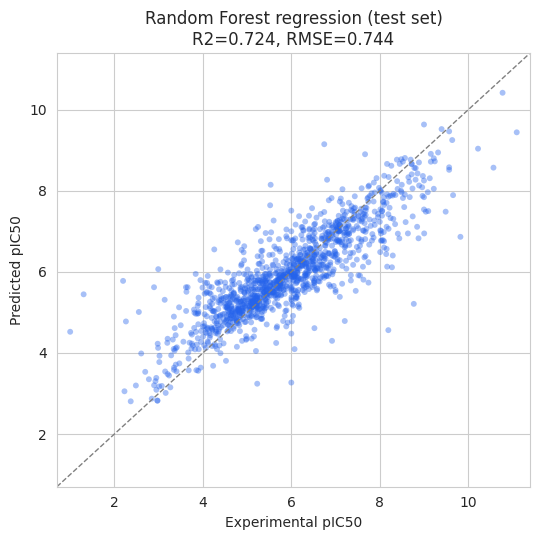

In [14]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(y_test, pred_reg, alpha=0.4, s=18, color="#2563eb", edgecolor="none")
lims = [min(y_test.min(), pred_reg.min()) - 0.3, max(y_test.max(), pred_reg.max()) + 0.3]
ax.plot(lims, lims, "--", color="gray", linewidth=1)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Experimental pIC50"); ax.set_ylabel("Predicted pIC50")
ax.set_title(f"Random Forest regression (test set)\nR2={reg_metrics['test_R2']:.3f}, RMSE={reg_metrics['test_RMSE']:.3f}")
plt.tight_layout()
plt.savefig(f"{OUT}/fig1_predicted_vs_actual.png", dpi=150)
plt.show()

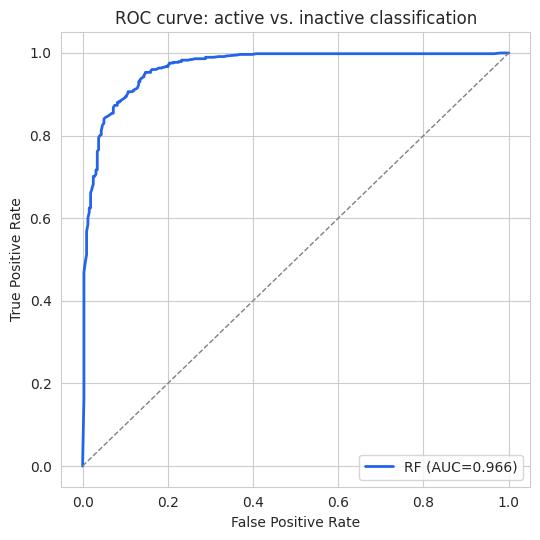

In [15]:
fpr, tpr, _ = roc_curve(yc_test, proba_clf)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(fpr, tpr, color="#2563eb", linewidth=2, label=f"RF (AUC={clf_metrics['test_AUC']:.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curve: active vs. inactive classification")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUT}/fig2_roc_curve.png", dpi=150)
plt.show()

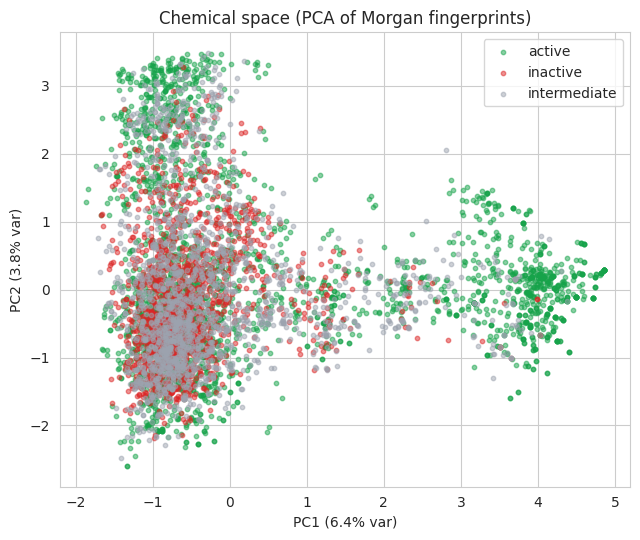

In [16]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_fp)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
colors = {"active": "#16a34a", "inactive": "#dc2626", "intermediate": "#9ca3af"}
for cls, c in colors.items():
    m = df_valid["class"] == cls
    ax.scatter(X_pca[m.values, 0], X_pca[m.values, 1], s=10, alpha=0.5, color=c, label=cls)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
ax.set_title("Chemical space (PCA of Morgan fingerprints)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/fig4_chemical_space_pca.png", dpi=150)
plt.show()

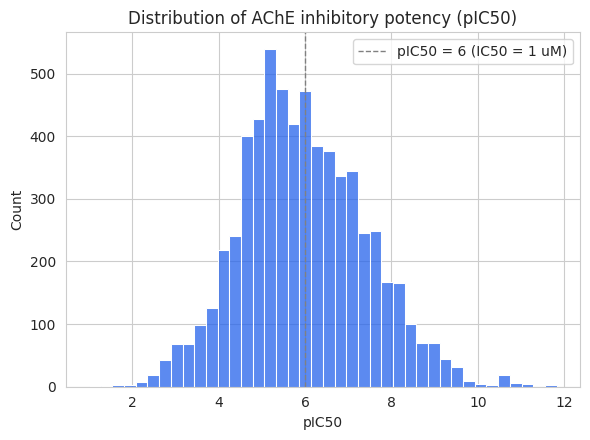

In [17]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.histplot(df_valid["pIC50"], bins=40, color="#2563eb", ax=ax)
ax.axvline(6, color="gray", linestyle="--", linewidth=1, label="pIC50 = 6 (IC50 = 1 uM)")
ax.set_xlabel("pIC50")
ax.set_title("Distribution of AChE inhibitory potency (pIC50)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/fig5_pIC50_distribution.png", dpi=150)
plt.show()

## 7. Interpretability — what is the model learning?

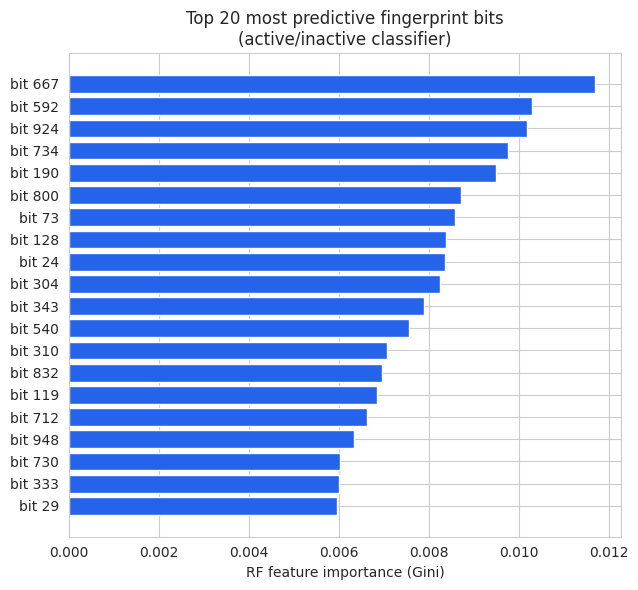

In [18]:
importances = rf_clf.feature_importances_
top_idx = np.argsort(importances)[::-1][:20]
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.barh([f"bit {i}" for i in top_idx][::-1], importances[top_idx][::-1], color="#2563eb")
ax.set_xlabel("RF feature importance (Gini)")
ax.set_title("Top 20 most predictive fingerprint bits\n(active/inactive classifier)")
plt.tight_layout()
plt.savefig(f"{OUT}/fig3_feature_importance.png", dpi=150)
plt.show()

In [19]:
# Map the top 6 bits back to real chemical substructures -- turns "bit 734"
# into an inspectable fragment a chemist can sanity-check.
top_bits = list(np.argsort(importances)[::-1][:6])
mols_for_bits, legends = [], []
active_smiles = df_valid.loc[df_valid["class"] == "active", "canonical_smiles"].tolist()

for bit in top_bits:
    for smi in active_smiles:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            continue
        bitinfo = {}
        AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=N_BITS, bitInfo=bitinfo)
        if bit in bitinfo:
            mols_for_bits.append((mol, bit, bitinfo))
            legends.append(f"bit {bit} (importance={importances[bit]:.4f})")
            break

img = Draw.DrawMorganBits(mols_for_bits, molsPerRow=3, legends=legends, subImgSize=(280, 280), useSVG=False)
with open(f"{OUT}/fig3b_substructures.png", "wb") as f:
    f.write(img if isinstance(img, (bytes, bytearray)) else img.encode())

display(Image(f"{OUT}/fig3b_substructures.png"))

AttributeError: 'PngImageFile' object has no attribute 'encode'

In [21]:
rand_reg_r2 = []
for i in range(N_RAND):
    y_shuf = np.random.RandomState(i).permutation(y_train)
    m = RandomForestRegressor(n_estimators=N_TREES, max_features="sqrt", n_jobs=-1, random_state=i)
    m.fit(X_train, y_shuf)
    r2 = r2_score(y_test, m.predict(X_test))
    rand_reg_r2.append(r2)
    tprint(f"  [regression y-randomization {i+1}/{N_RAND}] R2 = {r2:.3f}")

rand_reg_r2 = np.array(rand_reg_r2)
tprint(f"Real R2 = {reg_metrics['test_R2']:.3f}  |  Shuffled-label R2 = {rand_reg_r2.mean():.3f} +/- {rand_reg_r2.std():.3f}")

[ 594.5s]   [regression y-randomization 1/5] R2 = -0.217
[ 611.2s]   [regression y-randomization 2/5] R2 = -0.164
[ 625.3s]   [regression y-randomization 3/5] R2 = -0.181
[ 639.8s]   [regression y-randomization 4/5] R2 = -0.192
[ 650.1s]   [regression y-randomization 5/5] R2 = -0.181
[ 650.1s] Real R2 = 0.724  |  Shuffled-label R2 = -0.187 +/- 0.017


In [22]:
rand_clf_auc = []
for i in range(N_RAND):
    yc_shuf = np.random.RandomState(i).permutation(yc_train)
    m = RandomForestClassifier(n_estimators=N_TREES, n_jobs=-1, random_state=i)
    m.fit(Xc_train, yc_shuf)
    auc = roc_auc_score(yc_test, m.predict_proba(Xc_test)[:, 1])
    rand_clf_auc.append(auc)
    tprint(f"  [classification y-randomization {i+1}/{N_RAND}] AUC = {auc:.3f}")

rand_clf_auc = np.array(rand_clf_auc)
tprint(f"Real AUC = {clf_metrics['test_AUC']:.3f}  |  Shuffled-label AUC = {rand_clf_auc.mean():.3f} +/- {rand_clf_auc.std():.3f}")

[ 659.1s]   [classification y-randomization 1/5] AUC = 0.510
[ 663.4s]   [classification y-randomization 2/5] AUC = 0.507
[ 668.7s]   [classification y-randomization 3/5] AUC = 0.484
[ 674.1s]   [classification y-randomization 4/5] AUC = 0.495
[ 678.2s]   [classification y-randomization 5/5] AUC = 0.494
[ 678.2s] Real AUC = 0.966  |  Shuffled-label AUC = 0.498 +/- 0.009


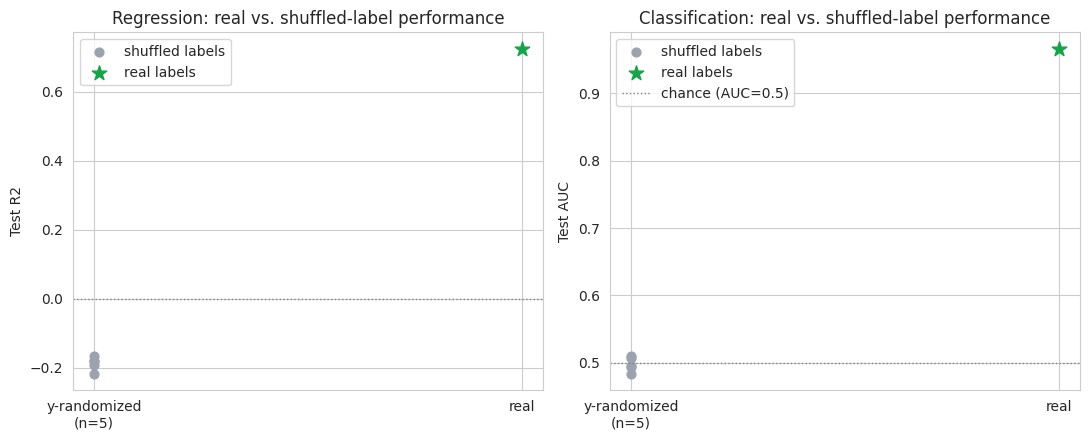


PASSED: shuffled-label performance collapsed toward chance, as expected for a model learning real signal.


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter([0]*N_RAND, rand_reg_r2, color="#9ca3af", s=40, zorder=2, label="shuffled labels")
axes[0].scatter([1], [reg_metrics["test_R2"]], color="#16a34a", s=120, marker="*", zorder=3, label="real labels")
axes[0].axhline(0, color="gray", linestyle=":", linewidth=1)
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["y-randomized\n(n=5)", "real"])
axes[0].set_ylabel("Test R2")
axes[0].set_title("Regression: real vs. shuffled-label performance")
axes[0].legend()

axes[1].scatter([0]*N_RAND, rand_clf_auc, color="#9ca3af", s=40, zorder=2, label="shuffled labels")
axes[1].scatter([1], [clf_metrics["test_AUC"]], color="#16a34a", s=120, marker="*", zorder=3, label="real labels")
axes[1].axhline(0.5, color="gray", linestyle=":", linewidth=1, label="chance (AUC=0.5)")
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["y-randomized\n(n=5)", "real"])
axes[1].set_ylabel("Test AUC")
axes[1].set_title("Classification: real vs. shuffled-label performance")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{OUT}/fig6_yrandomization_control.png", dpi=150)
plt.show()

if rand_reg_r2.mean() < 0.15 and abs(rand_clf_auc.mean() - 0.5) < 0.15:
    print("\nPASSED: shuffled-label performance collapsed toward chance, as expected for a model learning real signal.")
else:
    print("\nWARNING: shuffled-label performance did NOT collapse as expected -- investigate possible data leakage "
          "(e.g. near-duplicate/salt-form molecules split across train and test).")

In [24]:
with open(f"{OUT}/rf_classifier.pkl", "wb") as f:
    pickle.dump(rf_clf, f)
with open(f"{OUT}/rf_regressor.pkl", "wb") as f:
    pickle.dump(rf_reg, f)
df_valid.to_csv(f"{OUT}/ache_data_featurized_clean.csv", index=False)

all_metrics = {
    "n_compounds_total": int(len(df)),
    "n_compounds_featurized": int(len(df_valid)),
    "regression": reg_metrics,
    "classification": clf_metrics,
    "y_randomization": {
        "regression_R2_shuffled": rand_reg_r2.tolist(),
        "classification_AUC_shuffled": rand_clf_auc.tolist(),
    }
}
with open(f"{OUT}/metrics.json", "w") as f:
    json.dump(all_metrics, f, indent=2, default=float)

print("Saved all models, data, and metrics to", OUT)
print(json.dumps(all_metrics, indent=2, default=float))

Saved all models, data, and metrics to qsar_outputs
{
  "n_compounds_total": 6268,
  "n_compounds_featurized": 6268,
  "regression": {
    "test_R2": 0.7241834554571909,
    "test_RMSE": 0.7439123410347612,
    "test_MAE": 0.5266109438582506,
    "cv_R2_mean": 0.6866281127033508,
    "cv_R2_std": 0.025865163928116927
  },
  "classification": {
    "test_accuracy": 0.9128491620111732,
    "test_AUC": 0.9663308733890632,
    "test_F1": 0.9341216216216216,
    "cv_AUC_mean": 0.960314303268118,
    "cv_AUC_std": 0.00489315986671967
  },
  "y_randomization": {
    "regression_R2_shuffled": [
      -0.21688446771827952,
      -0.1640563317073822,
      -0.18051773480287148,
      -0.19249931262514974,
      -0.1809480441163811
    ],
    "classification_AUC_shuffled": [
      0.5096629005572971,
      0.5067104231974922,
      0.48379538923719956,
      0.4947889454893765,
      0.49396987112504354
    ]
  }
}
